# 12 — Pós-teste: O/E, ECE, curva de decisão e equidade

Lê **somente as previsões já gravadas pelo notebook 11** (`outputs/predictions/*_predicoes_teste.parquet`). **Não chama** `load_supervised_artifact` com blocos de teste e **não reabre o teste**: o G9 já está `executado` e este notebook não precisa (nem pode) alterá-lo.

Produz os números citados em `docs/decisoes.md` seção 9 e no `README.md` que, até aqui, não tinham código reprodutível no repositório (ver Auditoria_repo_limpo.md, item L5-02): O/E, inclinação de calibração e ECE por janela e por ano; curva de decisão (benefício líquido); e tabelas de desempenho/calibração por região, faixa etária e UF (essas três colunas já vêm nas previsões gravadas). Equidade por sexo/raça/zona exigiria um join adicional com a coorte publicada por `id_registro` — fica como próximo passo, não incluído aqui para manter este notebook simples e conferível.

In [ ]:
from pathlib import Path
import sys

ROOT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "supervised.yaml").exists())
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression

from src import config as C
from src.avaliacao import ece_quantis, mce_quantis, brier, metricas_por_grupo

C.carregar_dotenv()
C.garantir_diretorios()
print("Raiz:", ROOT_DIR)

## 1. Carregar as previsões do teste (gravadas pelo notebook 11)

Pega o manifesto **mais recente** do notebook 11 com `test_opened: true` e lê o parquet de previsões correspondente. Confere o hash do dataset contra o manifesto do artefato só como informação (não é obrigatório para continuar: o artefato pode ter sido regerado depois, ver item L3-01/#196 da auditoria).

In [4]:
import json

TABLES_DIR = C.OUTPUTS_DIR / "tables"
PRED_DIR = C.OUTPUTS_DIR / "predictions"

manifestos = sorted(TABLES_DIR.glob("11_validacao_final_*_manifesto.json"))
if not manifestos:
    raise FileNotFoundError(
        f"Nenhum manifesto 11_validacao_final_*_manifesto.json em {TABLES_DIR}. "
        "Este notebook so funciona depois do notebook 11 ter aberto o teste."
    )

manifesto_11 = json.loads(manifestos[-1].read_text(encoding="utf-8"))
if not manifesto_11.get("test_opened"):
    raise RuntimeError(f"{manifestos[-1].name} nao tem test_opened=true; nada para ler aqui.")

caminho_predicoes = Path(manifesto_11["artefatos"]["predicoes_teste"])
if not caminho_predicoes.is_absolute():
    caminho_predicoes = ROOT_DIR / caminho_predicoes
if not caminho_predicoes.exists():
    # caminho gravado pode ser de outra maquina (<REPO>\...); tenta pelo nome na pasta padrao
    caminho_predicoes = PRED_DIR / caminho_predicoes.name

pred = pd.read_parquet(caminho_predicoes)
limiar = float(manifesto_11["limiar_final"])
print("Previsoes:", caminho_predicoes, "| linhas:", len(pred), "| limiar:", limiar)
print("Blocos presentes:", sorted(pred["bloco"].unique()))
display(pred.head())

Previsoes: c:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\predictions\11_validacao_final_final_20261105T211527Z_predicoes_teste.parquet | linhas: 3035074 | limiar: 0.1178
Blocos presentes: ['test_pandemic', 'test_ref']


,bloco,y_true,y_prob,y_pred,id_registro,group_id,ano_internacao,sg_uf,regiao_residencia,faixa_etaria,sexo_categoria,limiar,modelo,cohort_kind
0,test_ref,0,0.016117,0,220945,31747767765641,2025,RJ,SUDESTE,<1,feminino,0.1178,boosting,final
1,test_ref,0,0.014949,0,220952,31748268960572,2025,BA,NORDESTE,1-4,feminino,0.1178,boosting,final
2,test_ref,0,0.383593,1,220955,31739284136517,2025,PE,NORDESTE,60-79,feminino,0.1178,boosting,final
3,test_ref,0,0.008756,0,220974,31751976667450,2025,PR,SUL,<1,feminino,0.1178,boosting,final
4,test_ref,1,0.434686,1,220976,31749495386727,2025,MT,CENTRO-OESTE,40-59,feminino,0.1178,boosting,final


## 2. O/E, inclinação de calibração e ECE por janela

In [ ]:
def inclinacao_calibracao(y_true, y_prob, eps: float = 1e-6):
    """Inclinacao (slope) de Cox: regressao logistica de y_true no logit(y_prob)."""
    p = np.clip(np.asarray(y_prob, dtype=float), eps, 1 - eps)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    modelo = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000)
    modelo.fit(logit, np.asarray(y_true, dtype=int))
    return float(modelo.coef_[0][0])


def resumo_janela(y_true, y_prob):
    y = np.asarray(y_true, dtype=int)
    p = np.asarray(y_prob, dtype=float)
    soma_p = float(p.sum())
    return {
        "n": int(len(y)), "positivos": int(y.sum()), "prevalencia": float(y.mean()),
        "o_e": (float(y.sum()) / soma_p) if soma_p > 0 else float("nan"),
        "inclinacao": inclinacao_calibracao(y, p),
        "ece_quantis": float(ece_quantis(y, p, n_bins=10)),
        "mce_quantis": float(mce_quantis(y, p, n_bins=10)),
        "brier": float(brier(y, p)),
    }


JANELAS = {
    "teste_a": pred["bloco"] == "test_ref",
    "pandemico_isolado": pred["bloco"] == "test_pandemic",
    "teste_b": pred["bloco"].isin(["test_ref", "test_pandemic"]),
}

linhas_janela = []
for nome, mascara in JANELAS.items():
    sub = pred.loc[mascara]
    if sub.empty:
        continue
    linhas_janela.append({"janela": nome, **resumo_janela(sub["y_true"], sub["y_prob"])})

calibracao_por_janela = pd.DataFrame(linhas_janela)
display(calibracao_por_janela.round(4))

## 3. O/E, inclinação e ECE por ano (`ano_internacao`, já vem nas previsões)

In [6]:
if "ano_internacao" not in pred.columns:
    raise KeyError("'ano_internacao' nao esta nas previsoes gravadas pelo notebook 11.")

linhas_ano = []
for ano, sub in pred.groupby("ano_internacao", observed=True):
    if len(sub) == 0:
        continue
    linhas_ano.append({"ano": int(ano), **resumo_janela(sub["y_true"], sub["y_prob"])})

calibracao_por_ano = pd.DataFrame(linhas_ano).sort_values("ano").reset_index(drop=True)
display(calibracao_por_ano.round(4))

c:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of pen

,ano,n,positivos,prevalencia,o_e,inclinacao,ece_quantis,mce_quantis,brier
0,2019,6509,781,0.1200,1.0986,0.9116,0.0133,0.8191,0.0871
1,2020,974415,272104,0.2792,1.5504,0.8479,0.0992,0.1349,0.1877
2,2021,1471091,413940,0.2814,1.8130,0.7765,0.1262,0.1589,0.1992
3,2022,470323,85051,0.1808,1.3720,0.9600,0.0490,0.1011,0.1257
4,2023,35697,3372,0.0945,1.0615,1.0259,0.0055,0.1617,0.0680
5,2024,34013,2795,0.0822,0.9970,0.9871,0.0014,0.1969,0.0616
6,2025,43026,3117,0.0724,0.9082,1.0291,0.0076,0.2621,0.0556


## 4. Curva de decisão (benefício líquido)

`beneficio = VP/n − FP/n × t/(1 − t)`, para uma grade de limiares `t`. Comparado com "alertar todos" e "alertar ninguém" (= 0).

Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\curva_decisao.png


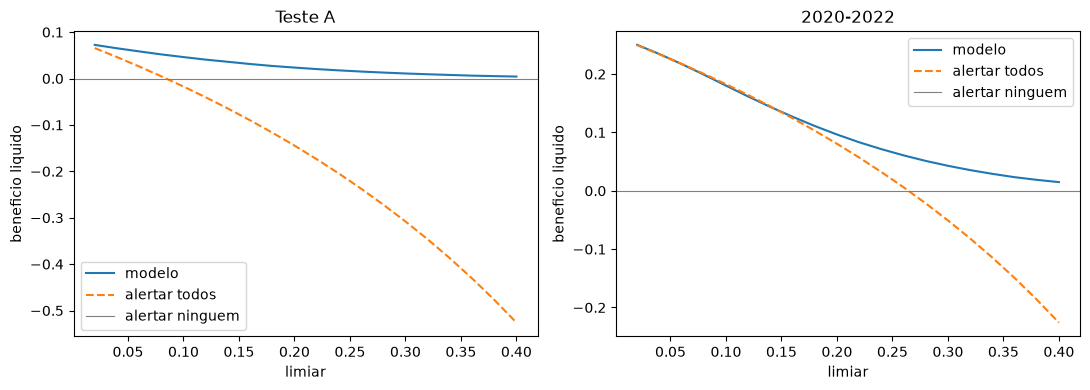

In [7]:
def curva_decisao(y_true, y_prob, limiares):
    y = np.asarray(y_true, dtype=int)
    p = np.asarray(y_prob, dtype=float)
    prevalencia = float(y.mean())
    linhas = []
    for t in limiares:
        alerta = (p >= t).astype(int)
        vp = int(((alerta == 1) & (y == 1)).sum())
        fp = int(((alerta == 1) & (y == 0)).sum())
        peso = t / (1 - t) if t < 1 else float("inf")
        beneficio_modelo = vp / len(y) - (fp / len(y)) * peso
        beneficio_todos = prevalencia - (1 - prevalencia) * peso
        linhas.append({
            "limiar": t, "alertas_por_100": 100 * alerta.mean(),
            "beneficio_modelo": beneficio_modelo, "beneficio_alertar_todos": beneficio_todos,
        })
    return pd.DataFrame(linhas)


limiares_grade = np.round(np.arange(0.02, 0.41, 0.02), 2)
curva_teste_a = curva_decisao(pred.loc[JANELAS["teste_a"], "y_true"], pred.loc[JANELAS["teste_a"], "y_prob"], limiares_grade)
curva_pandemia = curva_decisao(pred.loc[JANELAS["pandemico_isolado"], "y_true"], pred.loc[JANELAS["pandemico_isolado"], "y_prob"], limiares_grade)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for eixo, curva, titulo in ((eixos[0], curva_teste_a, "Teste A"), (eixos[1], curva_pandemia, "2020-2022")):
    eixo.plot(curva["limiar"], curva["beneficio_modelo"], label="modelo")
    eixo.plot(curva["limiar"], curva["beneficio_alertar_todos"], label="alertar todos", linestyle="--")
    eixo.axhline(0, color="grey", linewidth=0.8, label="alertar ninguem")
    eixo.set_title(titulo); eixo.set_xlabel("limiar"); eixo.set_ylabel("beneficio liquido"); eixo.legend()
fig.tight_layout()
CAMINHO_FIGURA_DECISAO = C.FIGURES_DIR / "curva_decisao.png"
fig.savefig(CAMINHO_FIGURA_DECISAO, dpi=150)
print("Figura salva em:", CAMINHO_FIGURA_DECISAO)

## 5. Desempenho e calibração por região e por faixa etária (Teste A)

`regiao_residencia` e `faixa_etaria` já vêm nas previsões gravadas (fazem parte de `COLUNAS_AUDITORIA`), então dá para medir sem reabrir nada.

,grupo,n,prevalencia,taxa_positivos,pr_auc,pr_auc_sobre_prev,auc,roc_auc,brier,o_e,f1,precision,recall,suprimido
0,SUDESTE,55419.0,0.0940,0.0940,0.3962,4.2162,0.8659,0.8659,0.0683,1.0081,0.3936,0.2580,0.8301,False
1,SUL,26466.0,0.0790,0.0790,0.3049,3.8594,0.8590,0.8590,0.0622,0.8533,0.3395,0.2130,0.8355,False
2,NORDESTE,16962.0,0.0767,0.0767,0.4277,5.5761,0.8891,0.8891,0.0545,1.2746,0.4641,0.3339,0.7610,False
3,CENTRO-OESTE,13303.0,0.0729,0.0729,0.3150,4.3206,0.8652,0.8652,0.0566,0.9348,0.3606,0.2336,0.7897,False
4,NORTE,7060.0,0.0695,0.0695,0.3599,5.1745,0.8704,0.8704,0.0526,1.1053,0.3905,0.2678,0.7210,False
5,AUSENTE,35.0,0.1143,0.1143,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


,grupo,n,prevalencia,taxa_positivos,pr_auc,pr_auc_sobre_prev,auc,roc_auc,brier,o_e,f1,precision,recall,suprimido
0,<1,32204.0,0.0135,0.0135,0.0626,4.6224,0.7471,0.7471,0.0130,1.0092,0.0967,0.1512,0.0711,False
1,1-4,23534.0,0.0099,0.0099,0.0499,5.0436,0.7646,0.7646,0.0096,0.9566,0.0710,0.1429,0.0472,False
2,60-79,19179.0,0.2012,0.2012,0.3905,1.9414,0.7037,0.7037,0.1455,0.9807,0.3850,0.2456,0.8909,False
3,80+,13170.0,0.2427,0.2427,0.4119,1.6973,0.6824,0.6824,0.1689,1.0013,0.4197,0.2696,0.9474,False
4,5-11,12570.0,0.0110,0.0110,0.0738,6.7193,0.7822,0.7822,0.0105,1.0533,0.0920,0.2222,0.0580,False
5,40-59,9732.0,0.1605,0.1605,0.3622,2.2567,0.7467,0.7467,0.1195,1.0161,0.3794,0.2473,0.8143,False
6,18-39,6474.0,0.0863,0.0863,0.2898,3.3569,0.8027,0.8027,0.0696,0.9811,0.3282,0.2171,0.6726,False
7,12-17,2382.0,0.0348,0.0348,0.1643,4.7147,0.8366,0.8366,0.0313,0.9936,0.2111,0.1810,0.2530,False


Figura salva em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\equidade_regiao.png


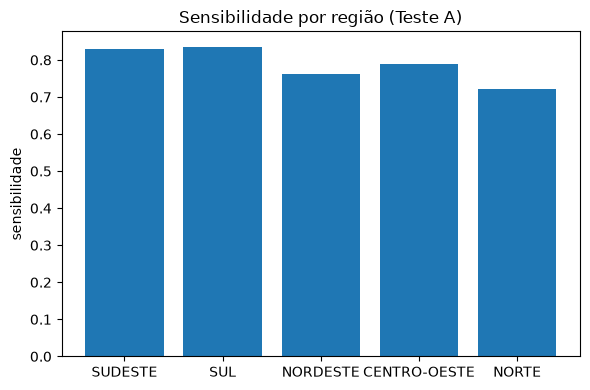

In [8]:
teste_a = pred.loc[JANELAS["teste_a"]].reset_index(drop=True)

equidade_regiao = metricas_por_grupo(
    teste_a, teste_a["y_true"], teste_a["y_prob"], coluna_grupo="regiao_residencia", limiar=limiar, min_n=100,
)
equidade_faixa_etaria = metricas_por_grupo(
    teste_a, teste_a["y_true"], teste_a["y_prob"], coluna_grupo="faixa_etaria", limiar=limiar, min_n=100,
)
display(equidade_regiao.round(4))
display(equidade_faixa_etaria.round(4))

fig2, eixo2 = plt.subplots(figsize=(6, 4))
eixo2.bar(equidade_regiao["grupo"], equidade_regiao["recall"])
eixo2.set_ylabel("sensibilidade"); eixo2.set_title("Sensibilidade por região (Teste A)")
fig2.tight_layout()
CAMINHO_FIGURA_EQUIDADE = C.FIGURES_DIR / "equidade_regiao.png"
fig2.savefig(CAMINHO_FIGURA_EQUIDADE, dpi=150)
print("Figura salva em:", CAMINHO_FIGURA_EQUIDADE)

## 6. Gravar as tabelas em `outputs/final/`

Nomes alinhados com o que `docs/decisoes.md` e o `README.md` já citam.

In [9]:
FINAL_DIR = C.OUTPUTS_DIR / "final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

calibracao_por_janela.to_csv(FINAL_DIR / "calibracao_por_janela.csv", index=False)
calibracao_por_ano.to_csv(FINAL_DIR / "calibracao_por_ano.csv", index=False)
curva_teste_a.to_csv(FINAL_DIR / "curva_decisao.csv", index=False)
curva_pandemia.to_csv(FINAL_DIR / "curva_decisao_pandemia.csv", index=False)
equidade_regiao.to_csv(FINAL_DIR / "tabelas_relatorio_regiao_residencia.csv", index=False)
equidade_faixa_etaria.to_csv(FINAL_DIR / "tabelas_relatorio_faixa_etaria.csv", index=False)

print("Tabelas gravadas em:", FINAL_DIR)
for p in sorted(FINAL_DIR.glob("*.csv")):
    print(" -", p.name)

Tabelas gravadas em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final
 - calibracao_por_ano.csv
 - calibracao_por_janela.csv
 - curva_decisao.csv
 - curva_decisao_pandemia.csv
 - tabelas_relatorio_faixa_etaria.csv
 - tabelas_relatorio_regiao_residencia.csv


## Próximo passo (não incluído aqui)

Equidade por `sexo_categoria`, `cs_raca` e `cs_zona` exige juntar estas previsões com `data/analytical/coorte_final.parquet` por `id_registro` (essas três colunas são features do modelo, não ficaram nas previsões gravadas). Isso não reabre o teste — é só reler colunas da coorte já publicada — mas foi deixado de fora deste notebook para mantê-lo simples e fácil de conferir linha a linha.